In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

In [2]:
print("TITANIC SURVIVAL PREDICTION")
df = pd.read_csv("titanic.csv")
print("Dataset shape:", df.shape)
print(df.head())

TITANIC SURVIVAL PREDICTION
Dataset shape: (891, 12)
   PassengerId  Survived  Pclass  ...     Fare Cabin  Embarked
0            1         0       3  ...   7.2500   NaN         S
1            2         1       1  ...  71.2833   C85         C
2            3         1       3  ...   7.9250   NaN         S
3            4         1       1  ...  53.1000  C123         S
4            5         0       3  ...   8.0500   NaN         S

[5 rows x 12 columns]


In [3]:
df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"], errors="ignore")
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Fare"] = df["Fare"].fillna(df["Fare"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df = pd.get_dummies(df, columns=["Sex", "Embarked"], drop_first=True, dtype=int)
X = df.drop(columns=["Survived"])
y = df["Survived"]
print("Features used:", list(X.columns))
print("Survived (1):", (y == 1).sum())
print("Did not survive (0):", (y == 0).sum())

Features used: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']
Survived (1): 342
Did not survive (0): 549


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training records:", X_train.shape[0])
print("Testing records :", X_test.shape[0])

Training records: 712
Testing records : 179


In [5]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Random Forest model training completed.")

Random Forest model training completed.


In [6]:
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Confusion Matrix:")
print(cm)
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Did Not Survive", "Survived"], zero_division=0))

Accuracy: 81.56 %
Confusion Matrix:
[[96 14]
 [19 50]]
Classification Report:
                 precision    recall  f1-score   support

Did Not Survive       0.83      0.87      0.85       110
       Survived       0.78      0.72      0.75        69

       accuracy                           0.82       179
      macro avg       0.81      0.80      0.80       179
   weighted avg       0.81      0.82      0.81       179



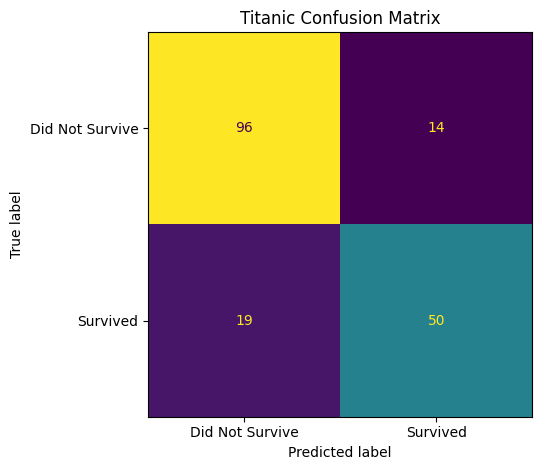

In [7]:
ConfusionMatrixDisplay(cm, display_labels=["Did Not Survive", "Survived"]).plot(colorbar=False, values_format="d")
plt.title("Titanic Confusion Matrix")
plt.tight_layout()
plt.show()

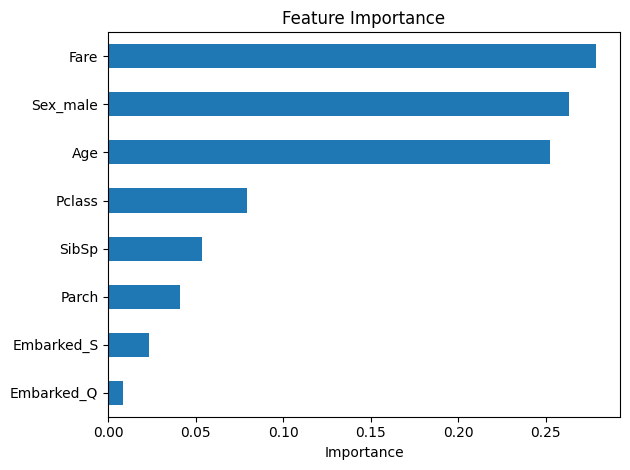

In [8]:
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=True)
importances.plot(kind="barh")
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()